# Extender el bloque 1 (60 épocas, paciencia 10) · continúa desde lo ya aprendido
Este cuaderno **no entrena desde cero**: carga los checkpoints de `results_colab/` (pesos + optimizador) y sigue entrenando hasta 60 épocas. Se ejecutó antes con 30 épocas y paciencia 6; varias redes (Transformer, CNN, GRU residual…) llegaron al tope con la mejor época al final, y alguna (p. ej. `mlp_dir` semilla 17) se detuvo antes de tiempo por la paciencia corta.

- Todo lo que ya tenía 60 épocas se omite; lo demás continúa. Si se corta Colab, vuelve a ejecutar todo.
- Al terminar regenera `tabla_principal.csv` y las figuras en `results_colab/`.
- El conteo de épocas (`epocas`, `epocas_meta`) y el tiempo acumulado quedan en cada `semilla_*.json` (para el costo de cómputo del artículo).
- Tiempo estimado en T4: ~30–40 min (los Transformers son lo más lento y van al final).

In [1]:
from pathlib import Path
import subprocess, sys

try:
    from google.colab import drive
    drive.mount("/content/drive")
    RAIZ_ = Path("/content/drive/MyDrive/MIA07 REDES NEURONALES Y APRENDIZAJE PROFUNDO")
    PROYECTO = next((c for c in (RAIZ_ / "23 PROYECTO FINAL" / "02_Repositorio_Codigo", RAIZ_ / "23 PROYECTO FINAL" / "04 PROYECTO COES DEMANDA",
                                 RAIZ_ / "24 PREVIOS PROYECTO FINAL" / "04 PROYECTO COES DEMANDA") if (c / "src" / "exp_v2.py").is_file()),
                    RAIZ_ / "23 PROYECTO FINAL" / "02_Repositorio_Codigo")
except ImportError:                       # ejecución local
    PROYECTO = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
if not (PROYECTO / "src" / "experimento.py").is_file():
    raise FileNotFoundError(f"Ajusta PROYECTO; no encuentro src/experimento.py en {PROYECTO}")
print("Proyecto:", PROYECTO)

Mounted at /content/drive
Proyecto: /content/drive/MyDrive/MIA07 REDES NEURONALES Y APRENDIZAJE PROFUNDO/23 PROYECTO FINAL/04 PROYECTO COES DEMANDA


In [2]:
import importlib.util
if importlib.util.find_spec("holidays") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "holidays"], check=True)
import torch
print("PyTorch", torch.__version__, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no hay (usa CPU, será lento)")

# Datos: si falta el CSV limpio, se descargan del portal del COES (~1 min)
if not (PROYECTO / "data" / "coes_demanda_limpio.csv").is_file():
    subprocess.run([sys.executable, str(PROYECTO / "coes_descarga.py"), "--salida", str(PROYECTO / "data")], check=True, cwd=PROYECTO)
else:
    print("Datos presentes:", (PROYECTO / "data" / "coes_demanda_limpio.csv").name)

PyTorch 2.11.0+cu130 | GPU: Tesla T4
Datos presentes: coes_demanda_limpio.csv


## Configuración de la corrida
- `MODO = "rapido"`: prueba de humo (1 semilla, pocos datos, minutos). `MODO = "completo"`: 3 semillas y todos los modelos y ablaciones.
- Los resultados se guardan en `results_colab/` (no pisan los de la PC).

In [3]:
MODO = "completo"            # no cambiar: se extienden los resultados de results_colab/
SEMILLAS = [17, 42, 73] if MODO == "completo" else [17]
PASO = 3 if MODO == "completo" else 24       # horas entre orígenes de entrenamiento
EPOCAS, PACIENCIA = (60, 10) if MODO == "completo" else (3, 2)
SALIDA = "results_colab" if MODO == "completo" else "results_colab_rapido"
HILOS = 2

import os

def ejecutar(*extra):
    cmd = [sys.executable, "-u", "src/experimento.py", "--resultados", SALIDA, "--hilos", str(HILOS), *extra]
    p = subprocess.Popen(cmd, cwd=PROYECTO, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    for linea in p.stdout:
        if "Warning" not in linea:
            print(linea, end="")
    if p.wait() != 0:
        raise RuntimeError("falló: " + " ".join(extra))
    os.sync()   # fuerza a Drive a escribir lo guardado

comun = ["--paso", str(PASO), "--epocas", str(EPOCAS), "--paciencia", str(PACIENCIA), "--semillas", *map(str, SEMILLAS)]
EXPERIMENTOS = [   # (nombre, argumentos)
    ("mlp_res",        ["--modelo", "mlp", "--residual"]),
    ("mlp_dir",        ["--modelo", "mlp"]),
    ("dlinear_res",    ["--modelo", "dlinear", "--residual"]),
    ("cnn_res",        ["--modelo", "cnn", "--residual"]),
    ("gru_res",        ["--modelo", "gru", "--residual"]),
    ("lstm_res",       ["--modelo", "lstm", "--residual"]),
    ("transformer_res",["--modelo", "transformer", "--residual"]),
    # ablaciones sobre GRU (cada una cambia UN factor)
    ("gru_dir",        ["--modelo", "gru"]),
    ("gru_res_sincal", ["--modelo", "gru", "--residual", "--sin_calendario"]),
    ("gru_res_L24",    ["--modelo", "gru", "--residual", "--L", "24"]),
    ("gru_res_L72",    ["--modelo", "gru", "--residual", "--L", "72"]),
    ("transformer_dir",["--modelo", "transformer"]),
]

## Líneas base (persistencia, estacional, programación del COES, Ridge)

In [4]:
ejecutar("--modelo", "base", "--nombre", "base")

base ya calculada, se omite (usa --rehacer)


## Entrenamiento de las redes
Cada experimento imprime la pérdida por época. Si se corta, **vuelve a ejecutar esta celda**: reanuda desde el último checkpoint y omite lo ya terminado. Los pesos finales quedan en `results_colab/<experimento>/modelo_<semilla>.pt`.

In [5]:
import time
t0 = time.time()
# los Transformers (lentos) al final
ORDEN = sorted(EXPERIMENTOS, key=lambda e: "transformer" in e[0])
for nombre, args in ORDEN:
    print()
    print(f"===== {nombre} =====")
    ejecutar(*args, "--nombre", nombre, *comun)
print()
print(f"Tiempo de esta sesión: {(time.time()-t0)/60:.1f} min")



===== mlp_res =====
==> mlp_res semilla 17: se EXTIENDE de 30 a 60 épocas desde lo aprendido
  [mlp s17] continúa desde la época 28 (lo ya aprendido)
  [mlp s17] ep29 train 0.0178 val 109.9 MW  13.0s
  [mlp s17] ep30 train 0.0178 val 106.4 MW  13.4s
  [mlp s17] ep31 train 0.0176 val 107.1 MW  13.8s
  [mlp s17] ep32 train 0.0176 val 107.9 MW  14.2s
==> mlp_res semilla 17: MAE 120.6 MW | MAPE 1.72% | RMSE 158.2 | params 360984 | 14.2s | Tesla T4
==> mlp_res semilla 42: se EXTIENDE de 30 a 60 épocas desde lo aprendido
  [mlp s42] continúa desde la época 30 (lo ya aprendido)
  [mlp s42] ep31 train 0.0178 val 105.3 MW  12.8s
  [mlp s42] ep32 train 0.0178 val 104.6 MW  13.2s
  [mlp s42] ep33 train 0.0176 val 104.3 MW  13.6s
  [mlp s42] ep34 train 0.0176 val 107.2 MW  14.0s
  [mlp s42] ep35 train 0.0176 val 107.4 MW  14.5s
  [mlp s42] ep36 train 0.0175 val 107.7 MW  14.9s
  [mlp s42] ep37 train 0.0176 val 108.6 MW  15.4s
  [mlp s42] ep38 train 0.0176 val 103.5 MW  15.9s
  [mlp s42] ep39 trai

## Resultados: tabla, comparaciones pareadas y figuras

,modelo,tipo,n_semillas,mae,mae_std,mape,mape_std,rmse,mae_laboral,mae_domingo,mae_feriado,n_param,seg_train
0,transformer_res,neuronal,3,93.00,0.90,1.33,0.01,127.69,91.97,86.11,167.35,102360,431.80
1,transformer_dir,neuronal,3,96.42,1.58,1.38,0.03,129.55,92.35,100.06,177.97,102360,447.30
2,gru_res_L72,neuronal,3,97.01,0.41,1.39,0.01,131.71,94.78,94.04,166.80,40600,29.47
3,cnn_res,neuronal,3,97.93,2.00,1.40,0.03,133.55,96.67,91.19,180.05,59624,83.47
4,coes_diaria,base,1,104.14,NaN,1.50,NaN,137.81,101.48,105.70,159.77,0,0.00
5,gru_dir,neuronal,3,111.13,8.53,1.58,0.11,147.89,109.90,101.01,210.37,40600,45.47
6,gru_res_L24,neuronal,3,112.50,2.88,1.62,0.04,155.04,106.29,120.65,228.44,40600,19.40
7,ridge_directo,base,1,112.80,NaN,1.61,NaN,160.12,105.12,107.29,278.86,0,0.00
8,ridge_residual,base,1,112.87,NaN,1.61,NaN,160.29,105.28,107.13,278.93,0,0.00
9,mlp_res,neuronal,3,115.00,5.08,1.65,0.07,153.53,112.45,111.67,192.12,360984,21.10


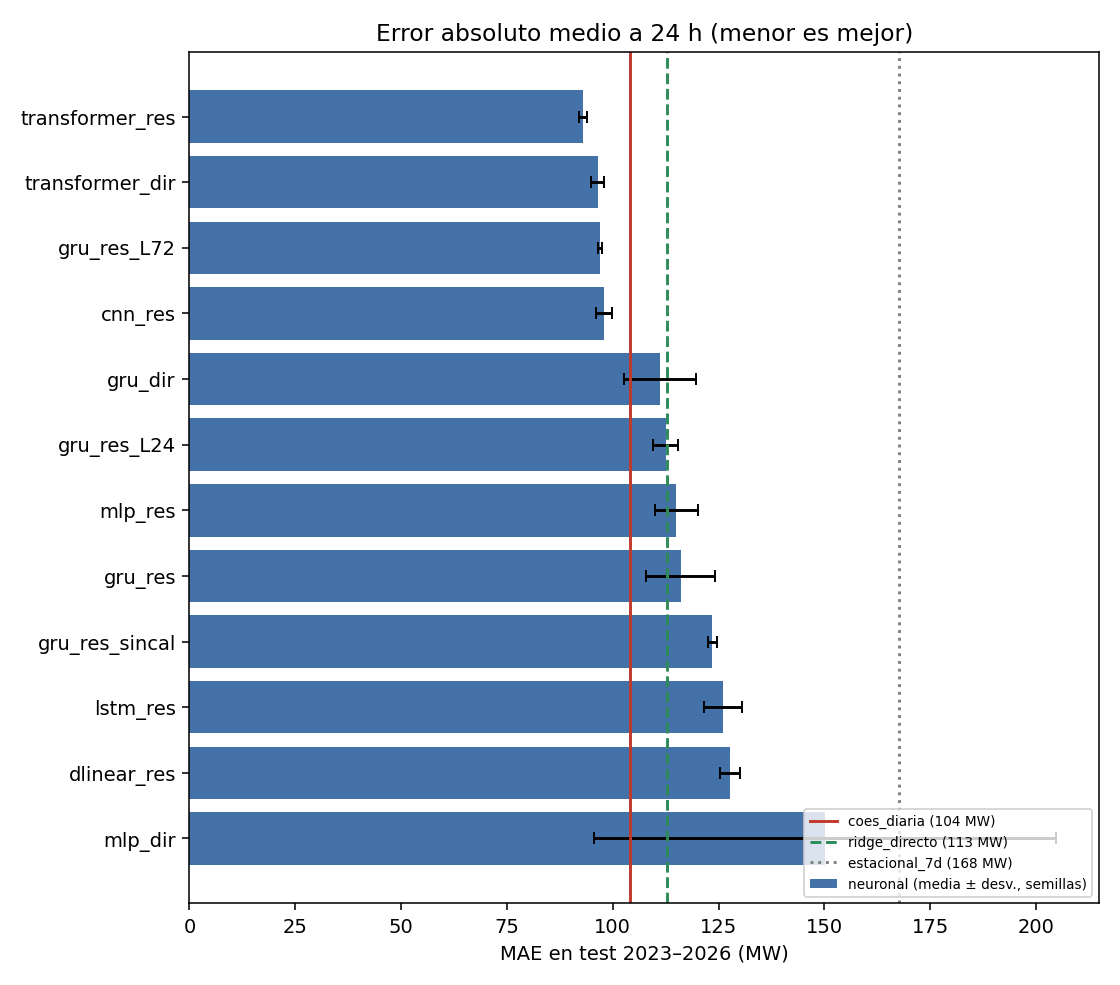

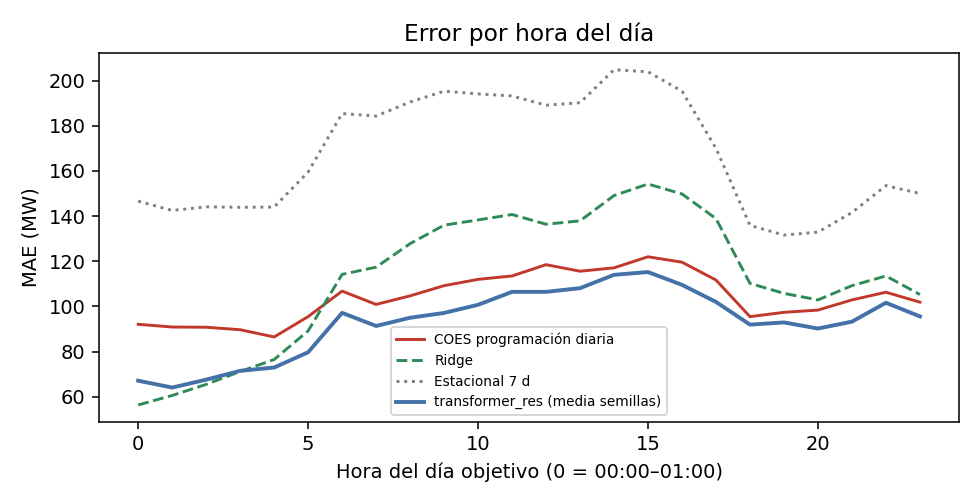

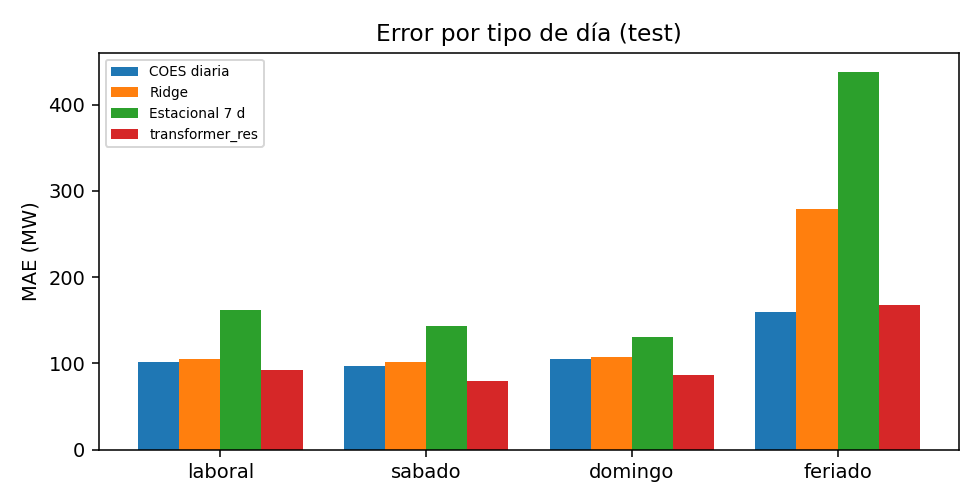

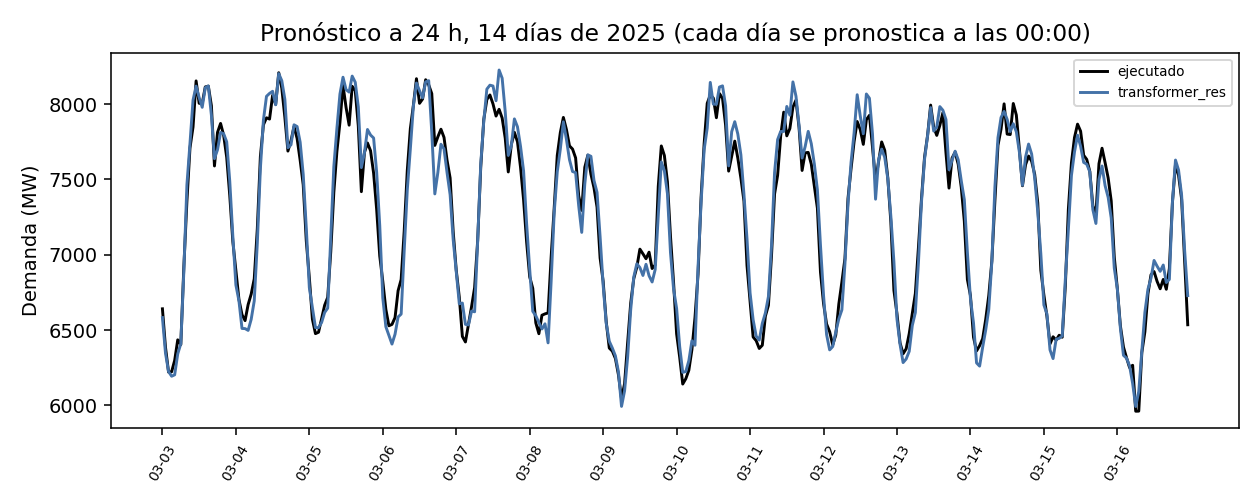

In [6]:
subprocess.run([sys.executable, "src/resumen.py", SALIDA], cwd=PROYECTO, check=True)
subprocess.run([sys.executable, "src/figuras.py", SALIDA], cwd=PROYECTO, check=True)
import pandas as pd
from IPython.display import display, Image
display(pd.read_csv(PROYECTO / SALIDA / "tabla_principal.csv").round(2))
for f in ("fig_mae_modelos", "fig_mae_por_hora", "fig_mae_tipo_dia", "fig_ejemplo_2semanas"):
    display(Image(str(PROYECTO / SALIDA / f"{f}.png")))

## Lectura
Reporta en el artículo: MAE/MAPE/RMSE (media ± desv. de 3 semillas), la tabla de ablaciones (residual vs. directo, con/sin calendario, ventana de 24/72/168 h), el error por hora y por tipo de día, y el costo (columna `seg_train` y el dispositivo en `semilla_*.json`). Las comparaciones pareadas (`comparaciones_pareadas.csv`) traen un IC 95 % por bootstrap de bloques de 7 días.